## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

visualisation:
- graph neural network (python package)
- add scientific form to heisenberg plot
- add automatic ticks formatting to heisenberg plot?

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- validate kurtosis and crest factor
- test border effects on kurtosis and crest factor
- test with data length of power of 2
- develop classifier
- clustering (e.g. k-means) using energy, kurtosis, crest factor is input features.
- 8 pages for manuscript
- normalise clustering
- look at effect of number of clusters
- learn about k-means and how it's used (reaserch)
- look at how it's used with dwpt
- explain and justify procedure for classification using research
- ksvd, knn
- settle on a method by next meeting

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [160]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [161]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [162]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.5, 0.5]  # amplitude of each sine wave
frequencies = [1, 10]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 30 / min(frequencies)  # duration of wave

trans_amp = [2 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db6"
levels = 4
mode = "symmetric"

sort_by = 'crest'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

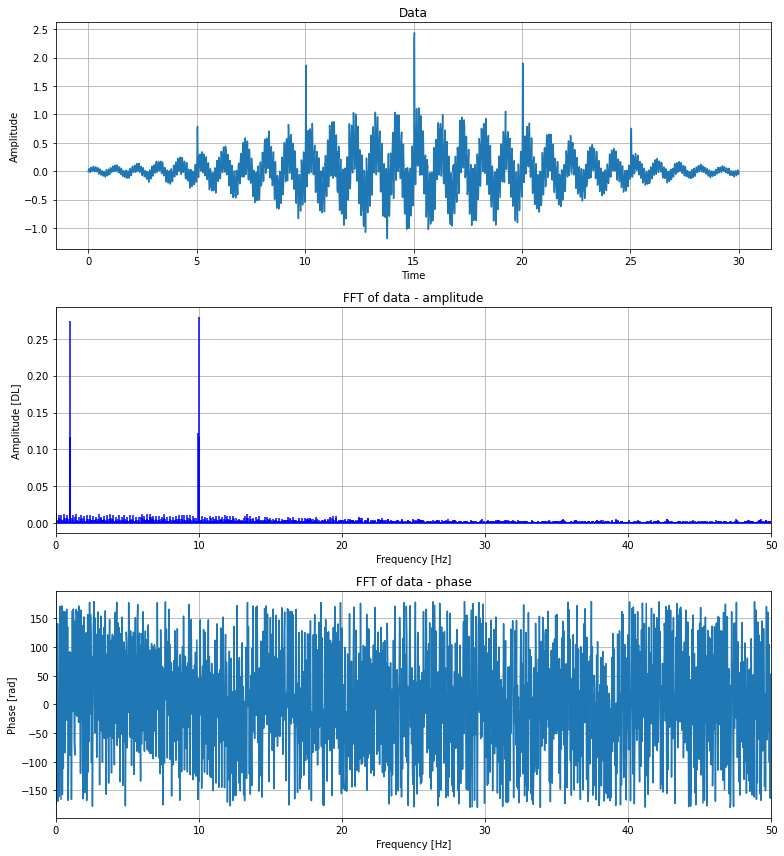

In [163]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [164]:
def calc_crest_factor(array):
    rms = np.sqrt(1 / len(array) * sum(array**2))
    return 10 * np.log10(max(array**2) / rms)


def calc_energy(array):
    return 1 / len(array) * sum(array**2)


def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [165]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_ob.get_level(order="freq"):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs = tr_ob.nodes2data(rec_nodes)
    inverse = inv.inv_dwpt(coeffs, wavelet)[:signal_length]
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = calc_energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = calc_crest_factor(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest))

plot the **`n_highest`** energy components (subbands).

sorted by: crest of rec


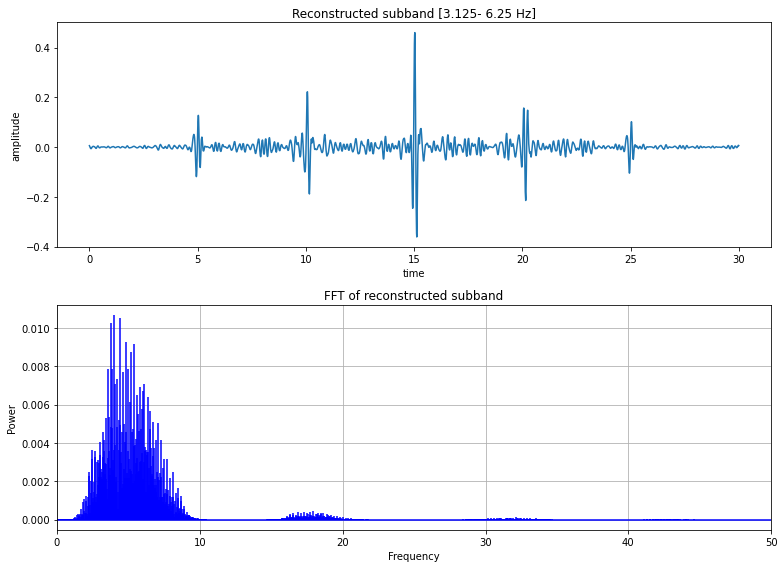

energy of recovered signal: 0.0013107744567749905
kurtosis of recovered signal: 50.284119039522764
crest factor of recovered signal: 7.676694298140875

energy of node coefficients: 0.019983196884549408
kurtosis of node coefficients: 27.33930078965641
crest factor of node coefficients: 9.759956130768725


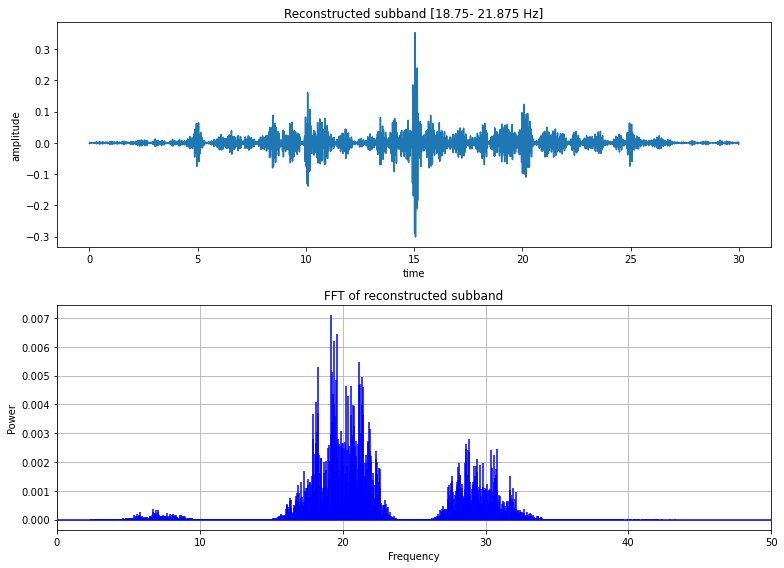

energy of recovered signal: 0.0006172876445433695
kurtosis of recovered signal: 37.71427663629323
crest factor of recovered signal: 7.012627850433261

energy of node coefficients: 0.009408288554621053
kurtosis of node coefficients: 13.607822764190871
crest factor of node coefficients: 6.897361678415681


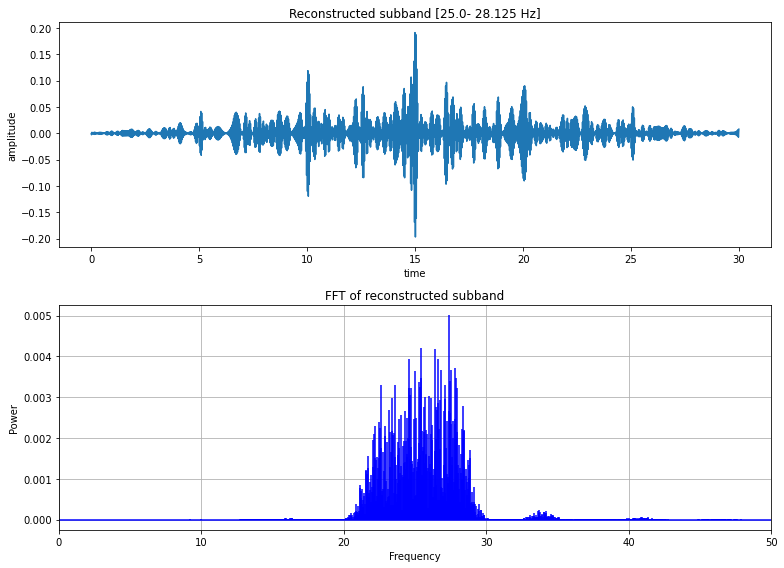

energy of recovered signal: 0.00040211893075753374
kurtosis of recovered signal: 17.809331083182375
crest factor of recovered signal: 2.857752789838128

energy of node coefficients: 0.006129756252130763
kurtosis of node coefficients: 4.6683170009464385
crest factor of node coefficients: 2.509566480903524


In [166]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, *_ = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {calc_energy(rec_wave)}")
        print(f"kurtosis of recovered signal: {sc.kurtosis(rec_wave)}")
        print(f"crest factor of recovered signal: {calc_crest_factor(rec_wave)}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
    return partial_rec



# sort reconstructed waves
sorted_rec = sort_nodes(rec, sort, sort_by)
print(f"sorted by: {sort_by} of {sort}")
# plot highest energy subbands
partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

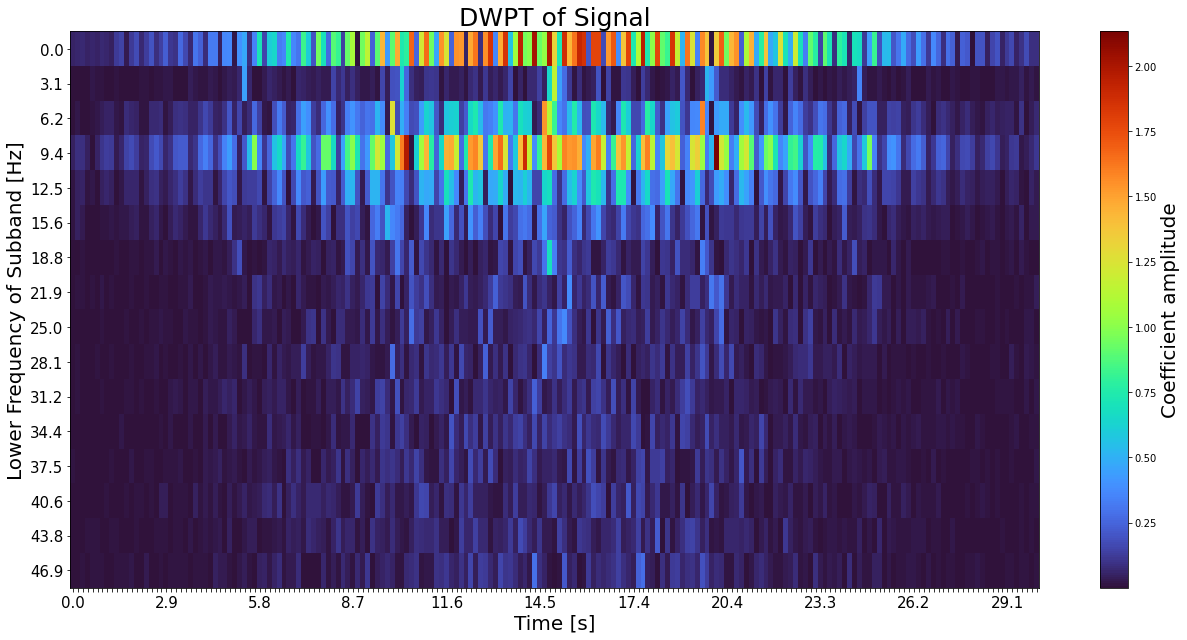

In [167]:
plot.heisenberg(tr_ob, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [191]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from numpy import std

# training data
data_train = []
for _,inverse,_,energy,kurtosis,crest in rec:
    data_train.append((energy,kurtosis,crest,max(abs(inverse))))

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)
# print(data_train_normalised)
# print('standard deviation after norm',std([i[0] for i in data_train_normalised]))

# training k-means algorithm
kmeans = KMeans(n_clusters=4)
kmeans.fit(data_train)

# get labels and clusters
labels = kmeans.labels_
centers = kmeans.cluster_centers_

print("Cluster labels:", labels)
print("Cluster centers:", centers)

# calculate weights
distances = kmeans.transform(data_train_normalised)
weights = np.sqrt(np.sum(distances, axis=1)**2)

# re-train
kmeans_weighted = KMeans(n_clusters=4)
kmeans_weighted.fit(data_train_normalised, sample_weight=weights)

# get labels
labels_weighted = kmeans_weighted.labels_
centers_weighted = kmeans_weighted.cluster_centers_

print("Cluster labels (weighted):", labels_weighted)
print("Cluster centers (weighted):", centers_weighted)


Cluster labels: [2 1 2 2 2 2 1 3 3 0 0 0 0 0 0 0]
Cluster centers: [[ 2.46481992e-04  3.76755244e+00 -3.66542532e+00  8.38075464e-02]
 [ 9.64031051e-04  4.39991978e+01  7.34466107e+00  4.06937753e-01]
 [ 2.19885215e-02  2.09679942e+00  2.96820254e+00  5.12706637e-01]
 [ 4.08336392e-04  1.52915548e+01  1.80728469e+00  1.76229520e-01]]
Cluster labels (weighted): [1 2 0 1 0 0 2 0 0 3 3 3 3 3 3 3]
Cluster centers (weighted): [[-0.24068045 -0.12903922  0.39864526  0.1080174 ]
 [ 2.59193066 -0.67214069  0.77531444  1.97479729]
 [-0.40410756  2.46581587  1.60680771  0.59192439]
 [-0.45063219 -0.42990363 -0.96978534 -0.80779279]]


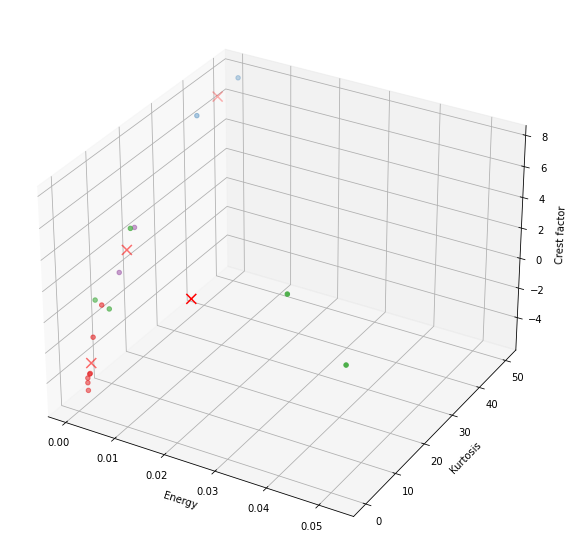

In [192]:
# 3d plot
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')

data_scatter = data_train
labels = labels
ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=[cmap(label) for label in labels]
)

# plot centres
centers = centers
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], c='red', marker='x', s=100)

ax.set_xlabel('Energy')
ax.set_ylabel('Kurtosis')
ax.set_zlabel('Crest factor')

# Show the 3D plot
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

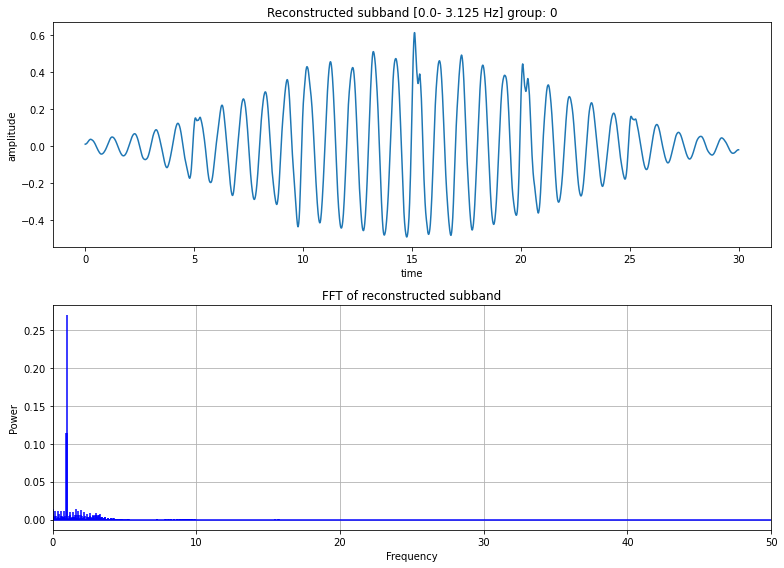

energy of recovered signal: 0.05067930457283741
kurtosis of recovered signal: -0.31887462572449055
crest factor of recovered signal: 2.251810627530989

energy of node coefficients: 0.7719617111330527
kurtosis of node coefficients: -0.20580652485326434
crest factor of node coefficients: 6.510709314054946


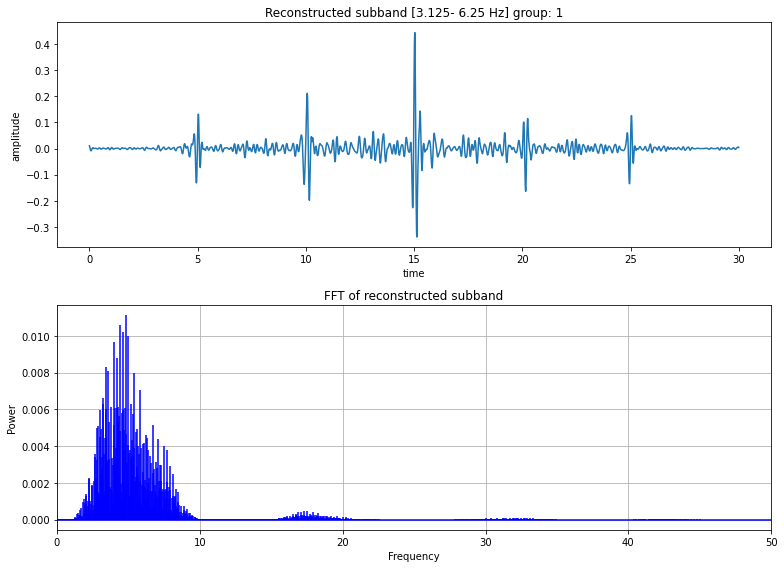

energy of recovered signal: 0.00127175627603901
kurtosis of recovered signal: 44.79117863869707
crest factor of recovered signal: 7.409325568410374

energy of node coefficients: 0.019389429187488778
kurtosis of node coefficients: 24.256231979587863
crest factor of node coefficients: 9.11628823892732


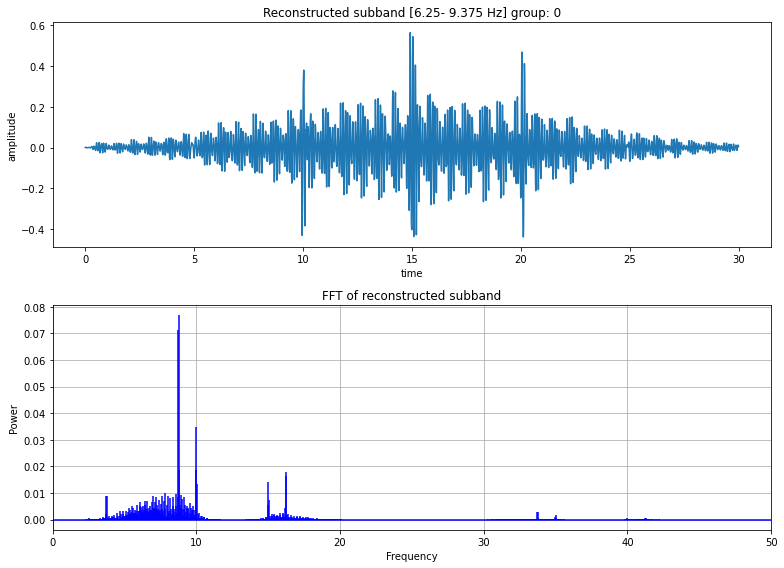

energy of recovered signal: 0.008449032145614706
kurtosis of recovered signal: 4.11488136789289
crest factor of recovered signal: 5.386912648250175

energy of node coefficients: 0.12871618415664798
kurtosis of node coefficients: 2.9285696795849505
crest factor of node coefficients: 7.664453050142532


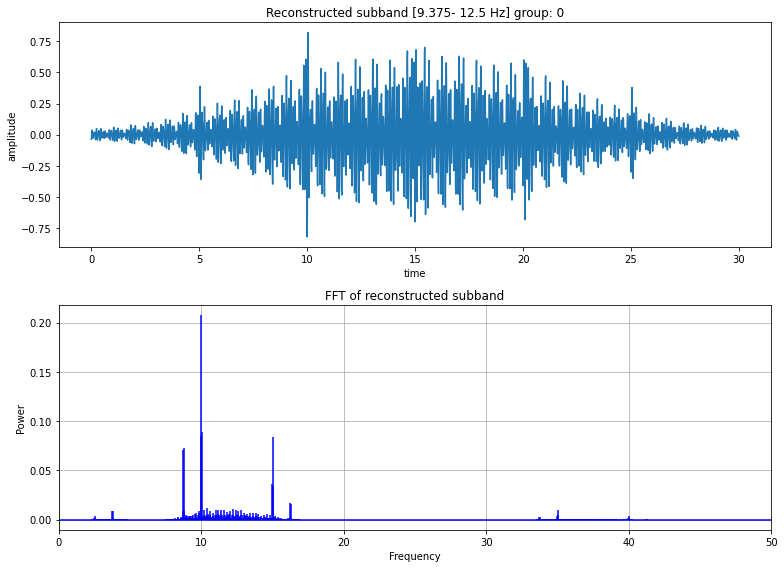

energy of recovered signal: 0.0410402931209666
kurtosis of recovered signal: 1.074553309717575
crest factor of recovered signal: 5.236009023912267

energy of node coefficients: 0.6252135820416019
kurtosis of node coefficients: -0.06942446579949291
crest factor of node coefficients: 7.279338645558448


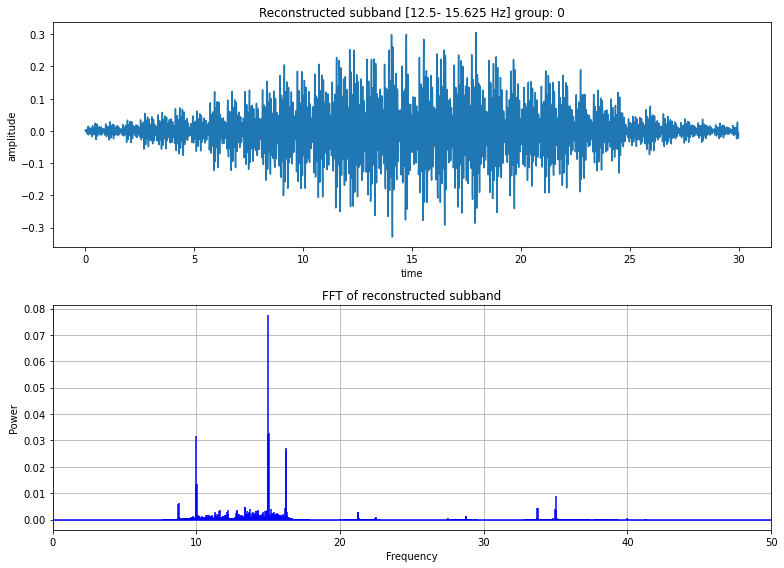

energy of recovered signal: 0.005906265993690943
kurtosis of recovered signal: 1.2896228117824515
crest factor of recovered signal: 1.4829248127043704

energy of node coefficients: 0.08998582545262165
kurtosis of node coefficients: -0.12786139728919954
crest factor of node coefficients: 1.8558974994229007


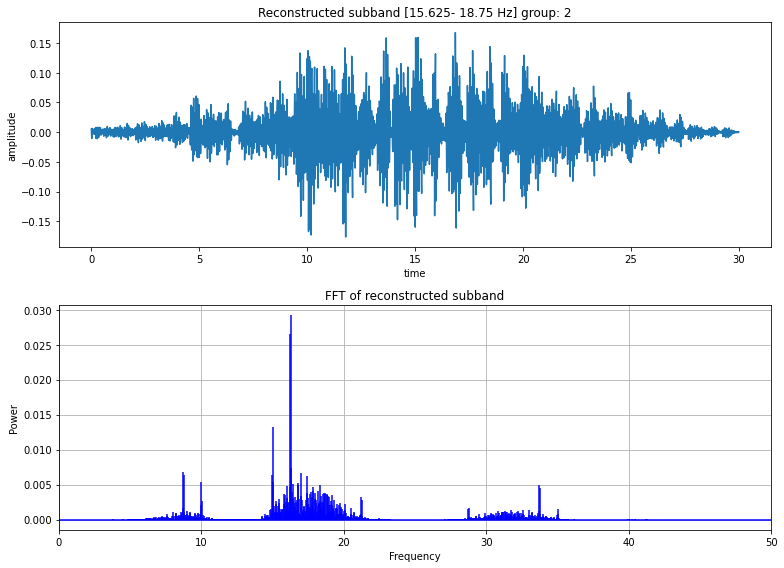

energy of recovered signal: 0.001530611060330132
kurtosis of recovered signal: 2.459229431769738
crest factor of recovered signal: -1.003832291975906

energy of node coefficients: 0.023343279351186637
kurtosis of node coefficients: 0.6561379950719886
crest factor of node coefficients: 0.983285419071901


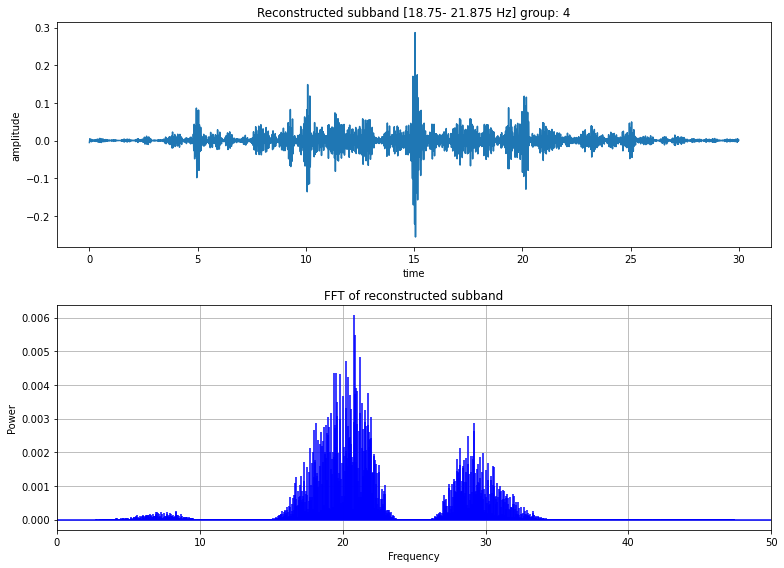

energy of recovered signal: 0.00048075528790962255
kurtosis of recovered signal: 29.43252042793067
crest factor of recovered signal: 5.7307413853119815

energy of node coefficients: 0.007328231368404112
kurtosis of node coefficients: 8.452543546619466
crest factor of node coefficients: 4.123678314244181


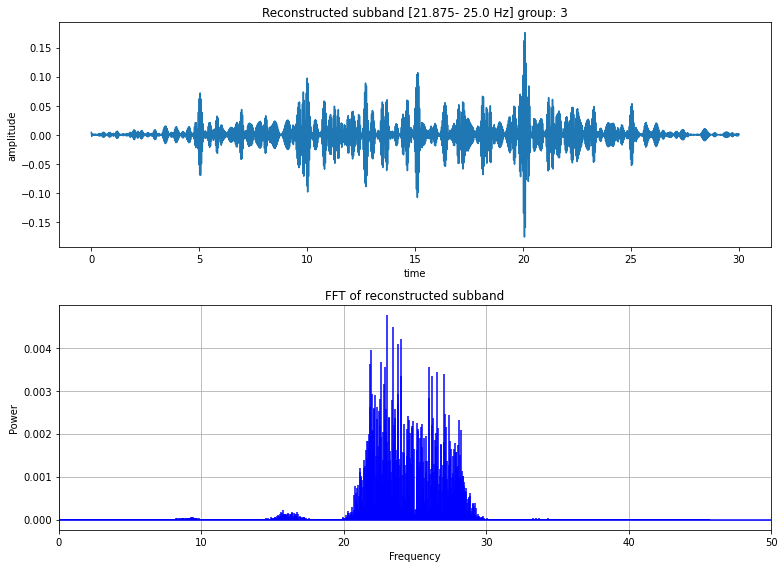

energy of recovered signal: 0.00035319826905122215
kurtosis of recovered signal: 15.122379762875166
crest factor of recovered signal: 2.175110444187568

energy of node coefficients: 0.005390067296799177
kurtosis of node coefficients: 6.0933420540733
crest factor of node coefficients: 3.728252375446473


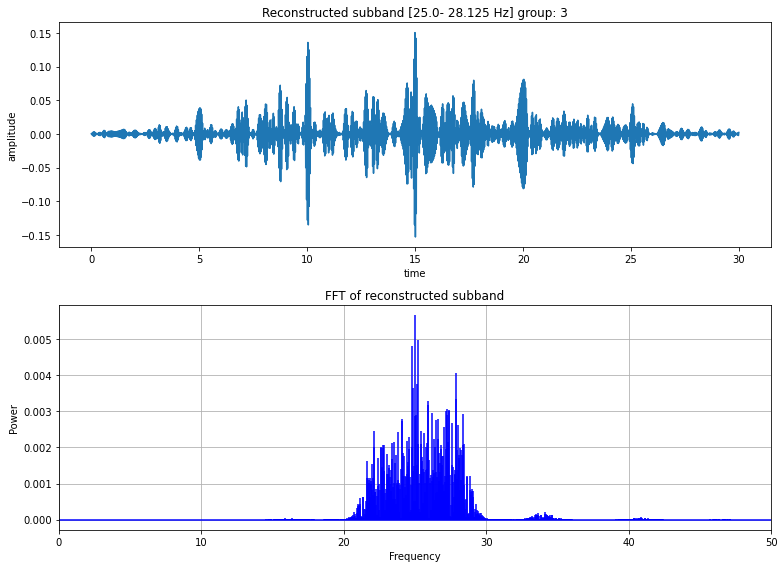

energy of recovered signal: 0.0003167345875267165
kurtosis of recovered signal: 15.536673595473612
crest factor of recovered signal: 1.1831638046523456

energy of node coefficients: 0.004825029795954366
kurtosis of node coefficients: 4.93141612198107
crest factor of node coefficients: 1.937532329101841


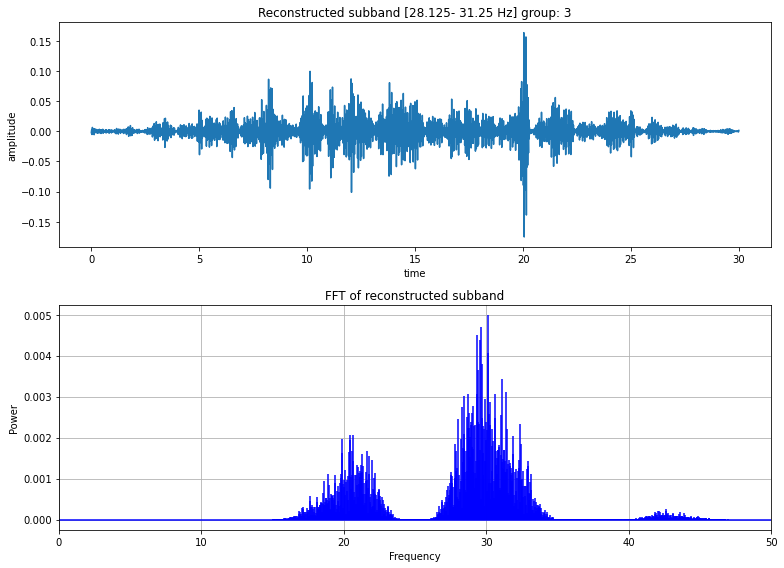

energy of recovered signal: 0.00032555471596425997
kurtosis of recovered signal: 12.997343450811025
crest factor of recovered signal: 2.310342546427035

energy of node coefficients: 0.00495963189412288
kurtosis of node coefficients: 8.925378358130045
crest factor of node coefficients: 4.4645781322756255


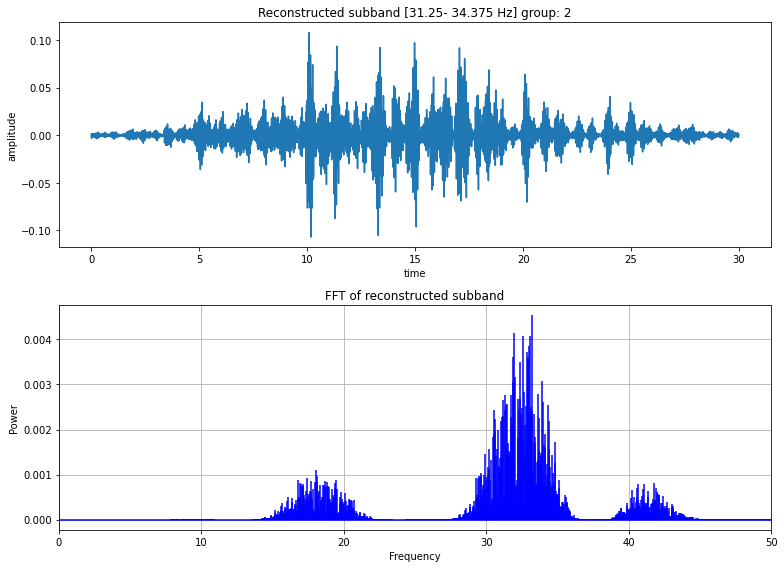

energy of recovered signal: 0.00029819501082498627
kurtosis of recovered signal: 6.333407961549073
crest factor of recovered signal: -1.7184769590603686

energy of node coefficients: 0.00454966257414722
kurtosis of node coefficients: 3.482152391208598
crest factor of node coefficients: 0.37835096402525387


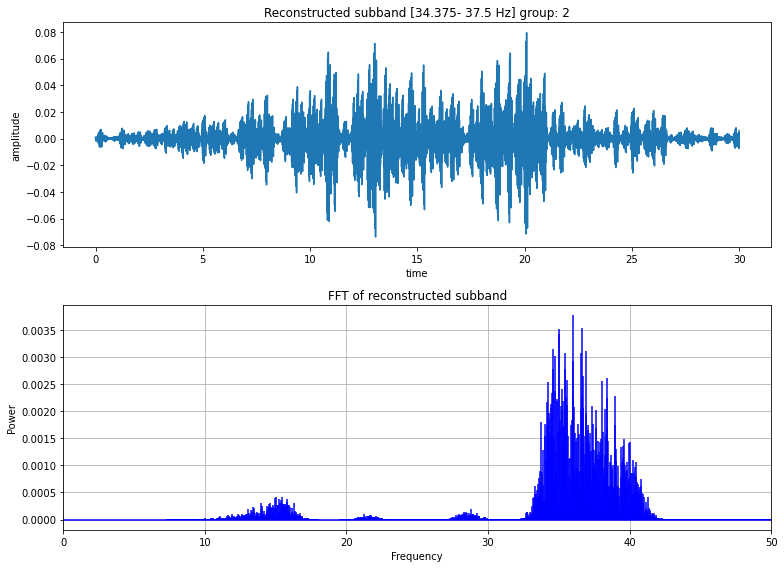

energy of recovered signal: 0.0002440579150803092
kurtosis of recovered signal: 3.213786599678574
crest factor of recovered signal: -3.929527351477363

energy of node coefficients: 0.0037241031682544263
kurtosis of node coefficients: 2.315314883118851
crest factor of node coefficients: -0.13918690732574937


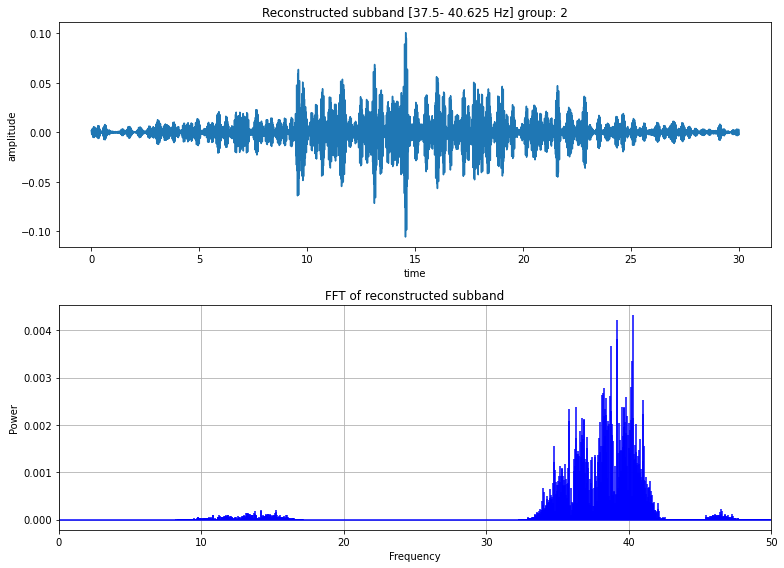

energy of recovered signal: 0.0002295345675032623
kurtosis of recovered signal: 5.447308888397195
crest factor of recovered signal: -1.308614937215141

energy of node coefficients: 0.0034999815261365997
kurtosis of node coefficients: 3.105491472337052
crest factor of node coefficients: 0.9622587144141864


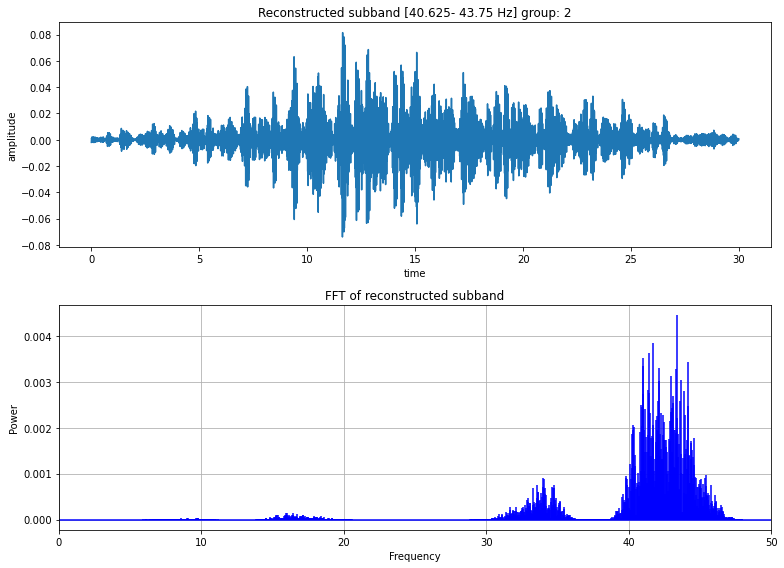

energy of recovered signal: 0.00025049349573846136
kurtosis of recovered signal: 2.9202469096666954
crest factor of recovered signal: -3.7691202485273934

energy of node coefficients: 0.003821221933706134
kurtosis of node coefficients: 2.231943727354796
crest factor of node coefficients: 0.014995553094213201


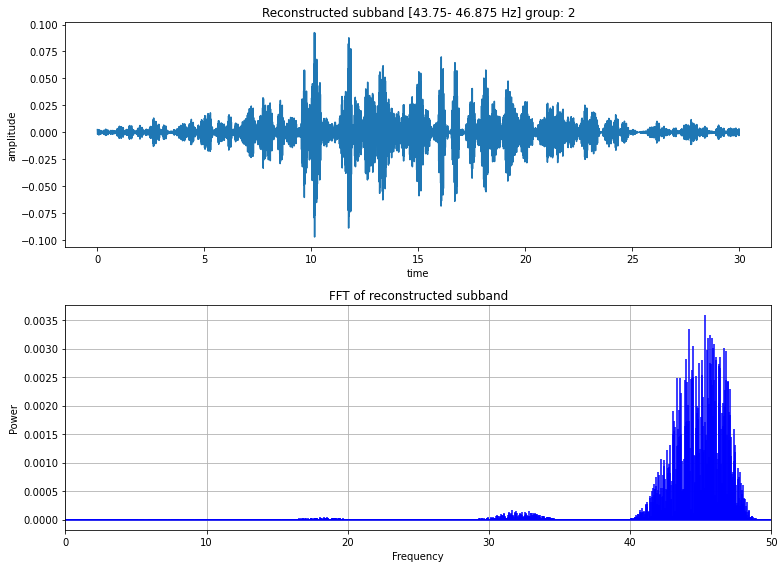

energy of recovered signal: 0.00025425618135489737
kurtosis of recovered signal: 5.582094741125674
crest factor of recovered signal: -2.2775976957599435

energy of node coefficients: 0.0038743348816224037
kurtosis of node coefficients: 3.6272585153952264
crest factor of node coefficients: 0.9014772982435273


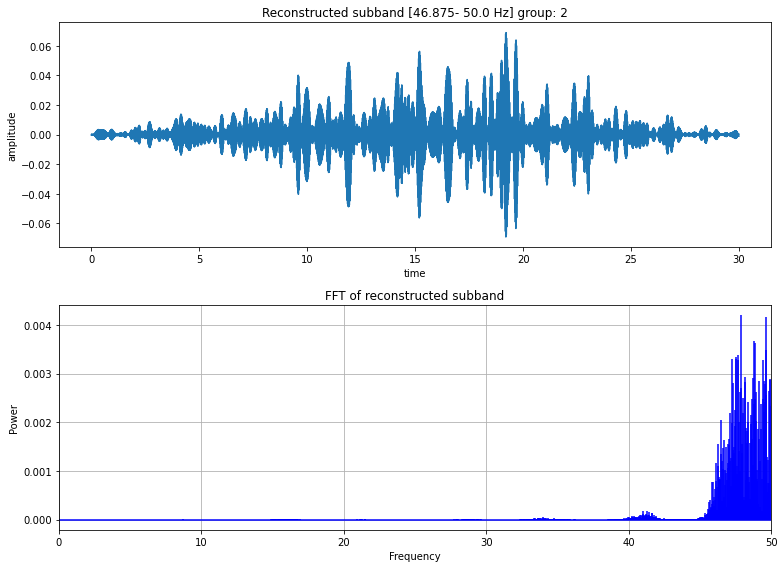

energy of recovered signal: 0.00022641524643363255
kurtosis of recovered signal: 3.1781108165686867
crest factor of recovered signal: -4.979560800942798

energy of node coefficients: 0.003455498635285049
kurtosis of node coefficients: 2.501886165588547
crest factor of node coefficients: -1.064146932253184


array([-0.00726177, -0.00188313,  0.02688227, ..., -0.03379743,
       -0.03976978, -0.01507058])

In [155]:
plot_reconstructions(rec,group=labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

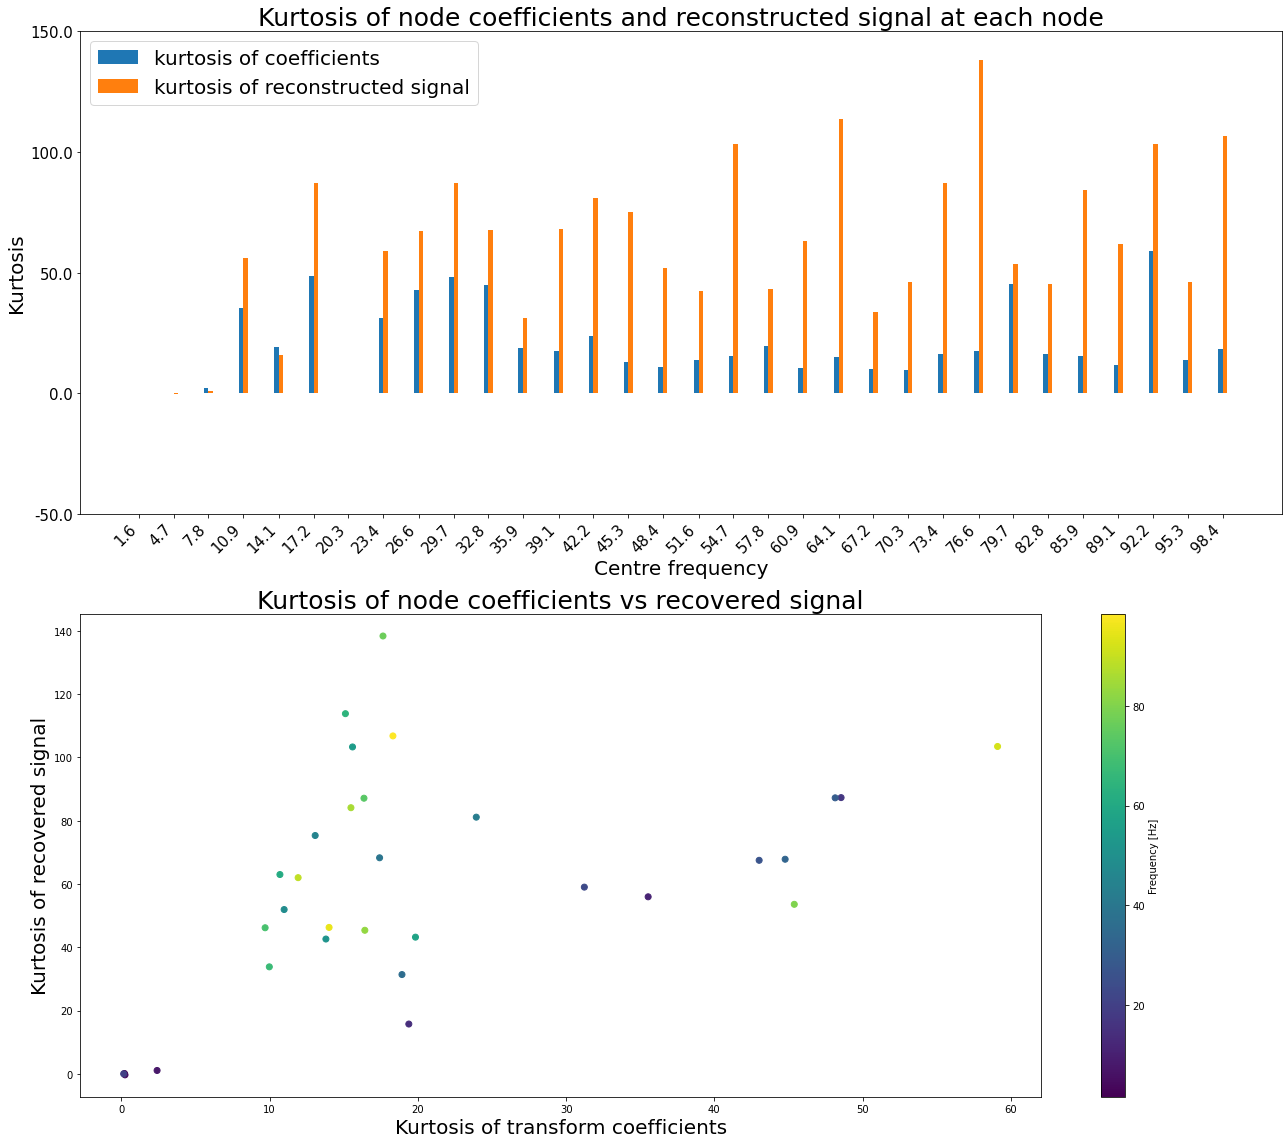

In [130]:
# gather data
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]
coef_kurtosis = [node.kurtosis for node, _, _ in rec]
kurtosis = [sc.kurtosis(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_kurtosis, width, align="center", label="kurtosis of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    kurtosis,
    width,
    align="center",
    label="kurtosis of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Kurtosis of node coefficients and reconstructed signal at each node", fontsize=25
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Kurtosis", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax[1].set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax[1].set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

In [16]:
# gather data
coef_crest = [node.crest_factor for node, _, _ in rec]
crest = [calc_crest_factor(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_crest, width, align="center", label="Crest factor of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    crest,
    width,
    align="center",
    label="Crest factor of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Crest factor of node coefficients and reconstructed signal at each node",
    fontsize=25,
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Crest factor [dB]", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_crest, crest, c=cent_freqs)
ax[1].set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax[1].set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

NameError: name 'rec' is not defined

### plot of reconstruction

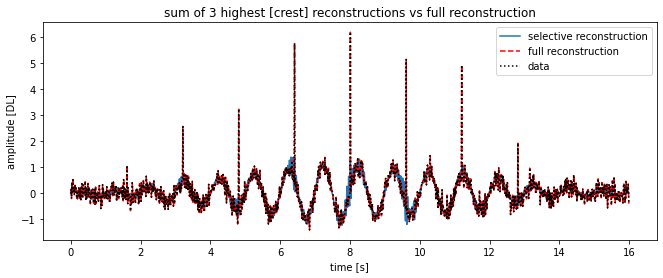

In [11]:
# plot sum of highest energy subbands
plt.figure(figsize=(11, 4))
plt.plot(t_plot, partial_rec)
plt.xlabel("time [s]")
plt.ylabel("amplitude [DL]")
plt.title(
    f"sum of {n_highest} highest [{sort_by}] reconstructions vs full reconstruction"
)

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()), wavelet)
plt.plot(t_plot, full_rec[:signal_length], "--r")
plt.plot(t_plot, data, ":k")
plt.legend(["selective reconstruction", "full reconstruction", "data"], loc="best")
plt.show()

### testing frequency sorting algorithm

In [8]:
my_frequencies = [node.path for node in tr_ob.get_level(order="freq")]
pywt_nodes = pywt._wavelet_packets.get_graycode_order(levels)
print("my nodes ordered by frequency:", my_frequencies)
print("pywt order:                   ", pywt_nodes)
print(my_frequencies == pywt_nodes)

my nodes ordered by frequency: ['aaaaaaaa', 'aaaaaaad', 'aaaaaadd', 'aaaaaada', 'aaaaadda', 'aaaaaddd', 'aaaaadad', 'aaaaadaa', 'aaaaddaa', 'aaaaddad', 'aaaadddd', 'aaaaddda', 'aaaadada', 'aaaadadd', 'aaaadaad', 'aaaadaaa', 'aaaddaaa', 'aaaddaad', 'aaaddadd', 'aaaddada', 'aaadddda', 'aaaddddd', 'aaadddad', 'aaadddaa', 'aaadadaa', 'aaadadad', 'aaadaddd', 'aaadadda', 'aaadaada', 'aaadaadd', 'aaadaaad', 'aaadaaaa', 'aaddaaaa', 'aaddaaad', 'aaddaadd', 'aaddaada', 'aaddadda', 'aaddaddd', 'aaddadad', 'aaddadaa', 'aaddddaa', 'aaddddad', 'aadddddd', 'aaddddda', 'aadddada', 'aadddadd', 'aadddaad', 'aadddaaa', 'aadadaaa', 'aadadaad', 'aadadadd', 'aadadada', 'aadaddda', 'aadadddd', 'aadaddad', 'aadaddaa', 'aadaadaa', 'aadaadad', 'aadaaddd', 'aadaadda', 'aadaaada', 'aadaaadd', 'aadaaaad', 'aadaaaaa', 'addaaaaa', 'addaaaad', 'addaaadd', 'addaaada', 'addaadda', 'addaaddd', 'addaadad', 'addaadaa', 'addaddaa', 'addaddad', 'addadddd', 'addaddda', 'addadada', 'addadadd', 'addadaad', 'addadaaa', 'addddaa